# TF-IDF Analysis - Mental Health Twitter Dataset

**TF-IDF (Term Frequency-Inverse Document Frequency)** identifies words that are:
- Frequent in one class but rare in the other
- Distinctive and discriminative for classification
- More meaningful than raw word counts

This analysis helps identify the **most characteristic words** for mental health posts vs control posts.

## 1. Setup and Load Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer

# Set style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [2]:
# Load the cleaned dataset
df = pd.read_csv('../data/processed/mental_health_cleaned.csv')

print(f"Dataset loaded: {len(df):,} rows")
print(f"Columns: {df.columns.tolist()[:10]}...") # Show first 10 columns

# Identify label and text columns
label_col = 'label'
text_col = 'cleaned_text'

print(f"\nUsing:")
print(f"  Text column: {text_col}")
print(f"  Label column: {label_col}")
print(f"  Labels: {df[label_col].unique()}")

Dataset loaded: 20,000 rows
Columns: ['Unnamed: 0', 'post_id', 'post_created', 'post_text', 'user_id', 'followers', 'friends', 'favourites', 'statuses', 'retweets']...

Using:
  Text column: cleaned_text
  Label column: label
  Labels: [1 0]


## 2. Calculate TF-IDF Scores

In [3]:
# Calculate TF-IDF for each label
print("Calculating TF-IDF scores...\n")
print("=" * 100)
print("TOP 10 TF-IDF WORDS BY LABEL")
print("=" * 100)

tfidf_results = {}

for label in sorted(df[label_col].unique()):
    # Get texts for this label
    subset_texts = df[df[label_col] == label][text_col].tolist()
    
    # Calculate TF-IDF
    vectorizer = TfidfVectorizer(
        max_features=100,      # Top 100 features
        stop_words='english',  # Remove common words
        min_df=5,              # Must appear in at least 5 documents
        max_df=0.8,            # Ignore if in more than 80% of documents
        ngram_range=(1, 1)     # Single words only
    )
    
    tfidf_matrix = vectorizer.fit_transform(subset_texts)
    
    # Get feature names and scores
    feature_names = vectorizer.get_feature_names_out()
    tfidf_scores = tfidf_matrix.sum(axis=0).A1  # Sum across all documents
    
    # Get top 10
    top_indices = tfidf_scores.argsort()[-10:][::-1]
    top_words = [(feature_names[i], tfidf_scores[i]) for i in top_indices]
    
    # Store results
    tfidf_results[label] = top_words
    
    # Print results
    label_name = "Mental Health Posts" if label == 1 else "Control Posts (Normal)"
    print(f"\nLABEL {label}: {label_name}")
    print("-" * 100)
    print(f"{'Rank':<6} {'Word':<25} {'TF-IDF Score':<15} {'Interpretation'}")
    print("-" * 100)
    
    for rank, (word, score) in enumerate(top_words, 1):
        print(f"{rank:<6} {word:<25} {score:<15.2f} {'Important & distinctive' if rank <= 3 else 'Relevant'}")

print("\n" + "=" * 100)

Calculating TF-IDF scores...

TOP 10 TF-IDF WORDS BY LABEL

LABEL 0: Control Posts (Normal)
----------------------------------------------------------------------------------------------------
Rank   Word                      TF-IDF Score    Interpretation
----------------------------------------------------------------------------------------------------
1      rt                        1094.69         Important & distinctive
2      im                        317.54          Important & distinctive
3      like                      266.07          Important & distinctive
4      just                      241.29          Relevant
5      dont                      213.18          Relevant
6      trump                     204.10          Relevant
7      yong                      191.06          Relevant
8      love                      179.00          Relevant
9      know                      169.37          Relevant
10     thank                     162.24          Relevant

LABEL 1: Mental 

## 3. Visualize TF-IDF Scores

Visualization saved to: ../data/processed/tfidf_analysis.png


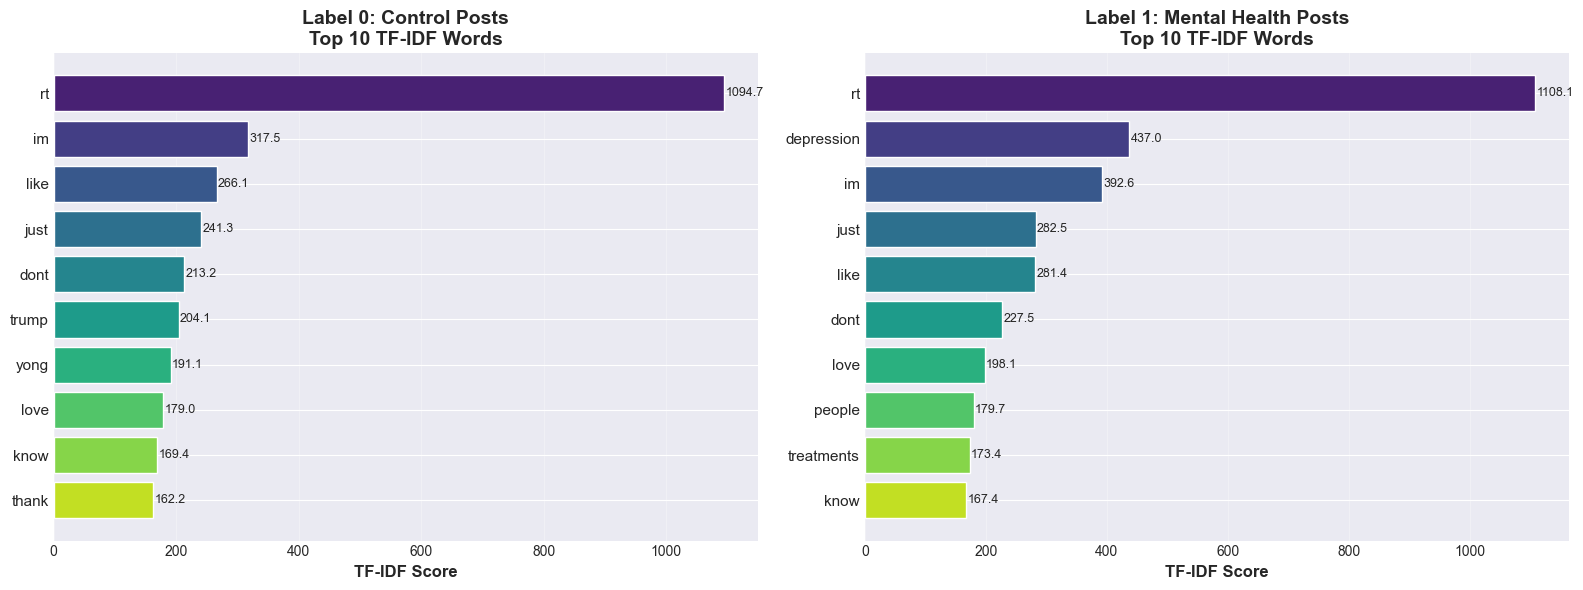

In [4]:
# Create visualization
n_labels = len(df[label_col].unique())
fig, axes = plt.subplots(1, n_labels, figsize=(16, 6))

if n_labels == 1:
    axes = [axes]

for idx, label in enumerate(sorted(df[label_col].unique())):
    top_words = [word for word, score in tfidf_results[label]]
    top_scores = [score for word, score in tfidf_results[label]]
    
    # Create horizontal bar chart
    colors = sns.color_palette('viridis', len(top_words))
    y_pos = np.arange(len(top_words))
    
    axes[idx].barh(y_pos, top_scores, color=colors)
    axes[idx].set_yticks(y_pos)
    axes[idx].set_yticklabels(top_words, fontsize=11)
    axes[idx].invert_yaxis()  # Highest score at top
    axes[idx].set_xlabel('TF-IDF Score', fontsize=12, fontweight='bold')
    
    label_name = "Mental Health Posts" if label == 1 else "Control Posts"
    axes[idx].set_title(f'Label {label}: {label_name}\nTop 10 TF-IDF Words', 
                        fontsize=14, fontweight='bold')
    axes[idx].grid(axis='x', alpha=0.3)
    
    # Add value labels
    for i, (word, score) in enumerate(zip(top_words, top_scores)):
        axes[idx].text(score + 2, i, f'{score:.1f}', va='center', fontsize=9)

plt.tight_layout()
plt.savefig('../data/processed/tfidf_analysis.png', dpi=300, bbox_inches='tight')
print("Visualization saved to: ../data/processed/tfidf_analysis.png")
plt.show()

## 4. Compare Unique Words Between Classes

In [5]:
# Find words unique to each class
if len(tfidf_results) == 2:
    labels_list = sorted(tfidf_results.keys())
    words_0 = set([word for word, score in tfidf_results[labels_list[0]]])
    words_1 = set([word for word, score in tfidf_results[labels_list[1]]])
    
    unique_0 = words_0 - words_1
    unique_1 = words_1 - words_0
    common = words_0 & words_1
    
    print("\n" + "=" * 100)
    print("VOCABULARY COMPARISON")
    print("=" * 100)
    
    print(f"\nWords unique to Label 0 (Control): {len(unique_0)}")
    print(f"  {', '.join(sorted(unique_0))}")
    
    print(f"\nWords unique to Label 1 (Mental Health): {len(unique_1)}")
    print(f"  {', '.join(sorted(unique_1))}")
    
    print(f"\nWords common to both: {len(common)}")
    print(f"  {', '.join(sorted(common))}")
    
    print("\n" + "=" * 100)
    print("INTERPRETATION:")
    print("=" * 100)
    print(f"- Vocabulary overlap: {len(common) / 10 * 100:.1f}% of top-10 words")
    print(f"- Unique control words: {len(unique_0)} - indicates distinctive normal communication")
    print(f"- Unique mental health words: {len(unique_1)} - indicates distinctive mental health language")
    print(f"- High uniqueness = easier classification")
    print("=" * 100)


VOCABULARY COMPARISON

Words unique to Label 0 (Control): 3
  thank, trump, yong

Words unique to Label 1 (Mental Health): 3
  depression, people, treatments

Words common to both: 7
  dont, im, just, know, like, love, rt

INTERPRETATION:
- Vocabulary overlap: 70.0% of top-10 words
- Unique control words: 3 - indicates distinctive normal communication
- Unique mental health words: 3 - indicates distinctive mental health language
- High uniqueness = easier classification


## 5. Export TF-IDF Results

In [6]:
# Save TF-IDF results to CSV
tfidf_data = []

for label, words in tfidf_results.items():
    for rank, (word, score) in enumerate(words, 1):
        tfidf_data.append({
            'label': label,
            'rank': rank,
            'word': word,
            'tfidf_score': score
        })

tfidf_df = pd.DataFrame(tfidf_data)
tfidf_df.to_csv('../data/processed/tfidf_top10.csv', index=False)

print("TF-IDF results saved to: ../data/processed/tfidf_top10.csv")
print(f"\nPreview:")
print(tfidf_df.head(10))

TF-IDF results saved to: ../data/processed/tfidf_top10.csv

Preview:
   label  rank   word  tfidf_score
0      0     1     rt  1094.689542
1      0     2     im   317.538334
2      0     3   like   266.072541
3      0     4   just   241.285426
4      0     5   dont   213.178151
5      0     6  trump   204.102728
6      0     7   yong   191.057170
7      0     8   love   178.995768
8      0     9   know   169.368058
9      0    10  thank   162.237098


## 6. Summary for IEEE Report

In [7]:
print("\n" + "=" * 100)
print("SUMMARY FOR IEEE REPORT")
print("=" * 100)

print("\n1. KEY FINDINGS:")
print("-" * 100)
for label in sorted(tfidf_results.keys()):
    label_name = "Mental Health" if label == 1 else "Control"
    top_3 = [word for word, score in tfidf_results[label][:3]]
    print(f"   Label {label} ({label_name}): Most distinctive words are '{', '.join(top_3)}'")

if len(tfidf_results) == 2:
    overlap = len(common) / 10 * 100
    print(f"\n2. VOCABULARY DISTINCTIVENESS:")
    print("-" * 100)
    print(f"   - Vocabulary overlap: {overlap:.1f}%")
    print(f"   - Distinctiveness: {100-overlap:.1f}%")
    print(f"   - Interpretation: {'High' if overlap < 30 else 'Moderate' if overlap < 60 else 'Low'} class separability")

print("\n" + "=" * 100)


SUMMARY FOR IEEE REPORT

1. KEY FINDINGS:
----------------------------------------------------------------------------------------------------
   Label 0 (Control): Most distinctive words are 'rt, im, like'
   Label 1 (Mental Health): Most distinctive words are 'rt, depression, im'

2. VOCABULARY DISTINCTIVENESS:
----------------------------------------------------------------------------------------------------
   - Vocabulary overlap: 70.0%
   - Distinctiveness: 30.0%
   - Interpretation: Low class separability

